# Deep Learning with PyTorch: Going Deeper with Convolutions (Part 4)

This notebook is the 4th installment in the **Deep Learning with PyTorch** series (continuing directly from the 3rd notebook). In this section, we move beyond basic Multi-Layer Perceptrons (MLPs) to explore **Convolutional Neural Networks (CNNs)**, regularization techniques, and advanced architectures like **Residual Connections (ResNets)**.

### Project Setup & Objectives:
* Implement foundational 2D convolutions and pooling layers.
* Build and train a baseline CNN on CIFAR-2 (Airplanes vs. Birds).
* Explore strategies to handle overfitting: **Width**, **Dropout**, and **Batch Normalization**.
* Implement deeper architectures using **Skip Connections (Residual Blocks)**

Importing the relevant packages

In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np
import collections

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [ ]:
from torchvision import datasets, transforms
data_path = '../data-unversioned/CIFAR/'

cifar10 = datasets.CIFAR10(
    data_path, train=True, download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4915, 0.4823, 0.4468),  #REFER NOTEBOOK 03_Classifying_Birds_vs_Planes_PyTorch_MLP.ipynb
                             (0.2470, 0.2435, 0.2616))  # regarding this calculation
    ]))

cifar10_val = datasets.CIFAR10(
    data_path, train=False, download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4915, 0.4823, 0.4468),
                             (0.2470, 0.2435, 0.2616))
    ]))

Files already downloaded and verified
Files already downloaded and verified


In [ ]:
label_map = {0: 0, 2: 1}
class_names = ['airplane', 'bird']
cifar2 = [(img, label_map[label])
          for img, label in cifar10
          if label in [0, 2]]
cifar2_val = [(img, label_map[label])
              for img, label in cifar10_val
              if label in [0, 2]]

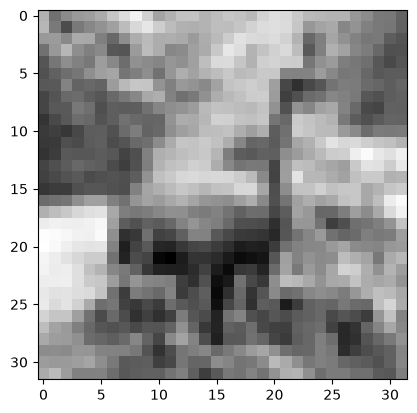

In [ ]:
img, _ = cifar2[0]
plt.imshow(img.mean(0), cmap='gray')
plt.show()

In [ ]:
conv = nn.Conv2d(3, 1, kernel_size=3, padding=1)
output = conv(img.unsqueeze(0))
img.unsqueeze(0).shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 1, 32, 32]))

In [ ]:
with torch.no_grad():
    conv.bias.zero_()

with torch.no_grad():
    conv.weight.fill_(1.0/9.0)

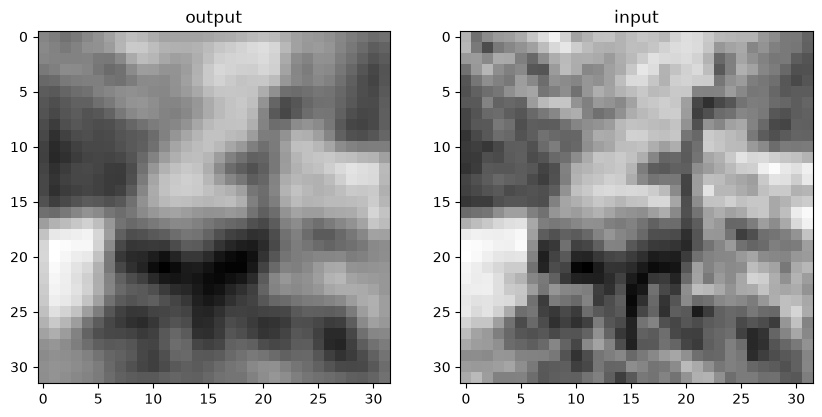

In [ ]:
output = conv(img.unsqueeze(0))

plt.figure(figsize=(10, 4.8))
ax1 = plt.subplot(1, 2, 1)
plt.title('output')
plt.imshow(output[0, 0].detach(), cmap='gray')
plt.subplot(1, 2, 2, sharex=ax1, sharey=ax1)
plt.imshow(img.mean(0), cmap='gray')
plt.title('input')
plt.show()

In [ ]:
conv = nn.Conv2d(3, 1, kernel_size=3, padding=1)

with torch.no_grad():
    conv.weight[:] = torch.tensor([[-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0]])
    conv.bias.zero_()

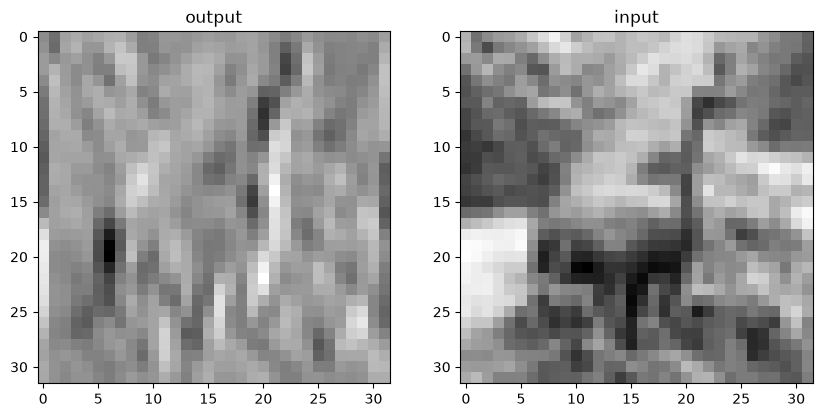

In [ ]:
output = conv(img.unsqueeze(0))

plt.figure(figsize=(10, 4.8))
ax1 = plt.subplot(1, 2, 1)
plt.title('output')
plt.imshow(output[0, 0].detach(), cmap='gray')
plt.subplot(1, 2, 2, sharex=ax1, sharey=ax1)
plt.imshow(img.mean(0), cmap='gray')
plt.title('input')
plt.show()

In [ ]:
pool = nn.MaxPool2d(2)
output = pool(img.unsqueeze(0))
img.unsqueeze(0).shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 3, 16, 16]))

subclassing the nn module with functional API

## Baseline Model Architecture

Here we define a standard CNN architecture containing convolutional layers followed by max pooling and fully connected layers.

In [ ]:
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 8, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(8*8*8, 32)
        self.fc2 = nn.Linear(32,2)

    def forward(self, x):
        out = F.max_pool2d(torch.tanh(self.conv1(x)), 2)
        out = F.max_pool2d(torch.tanh(self.conv2(out)), 2)
        out = out.view(-1, 8*8*8)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = Net()

numel_list = [p.numel() for p in model.parameters()]
sum(numel_list), numel_list



(18090, [432, 16, 1152, 8, 16384, 32, 64, 2])

In [ ]:
model(img.unsqueeze(0))

tensor([[-0.0005, -0.0270]], grad_fn=<AddmmBackward0>)

creating mini-batches to train

## Training Preparation

We configure data loaders for batching, verify the hardware accelerator (CUDA GPU), and define our standardized training and validation loops.

In [ ]:
train_loader = torch.utils.data.DataLoader(cifar2, batch_size=64, shuffle=False)

val_loader = torch.utils.data.DataLoader(cifar2_val, batch_size=64, shuffle=False)

In [ ]:
device = (torch.device('cuda') if torch.cuda.is_available()
         else torch.device('cpu'))
print(f"Training on device {device}.")

Training on device cuda.


In [ ]:
import datetime

def training_loop(n_epochs, optimizer, model, loss_fn, train_loader):
    for epoch in range(1, n_epochs +1):
        loss_train = 0
        for imgs, labels in train_loader:
            imgs = imgs.to(device=device)
            labels = labels.to(device=device)
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_train += loss.item()

        if epoch == 1 or epoch % 10 == 0:
            print('{} Epoch {}, Training Loss {}'.format(
                datetime.datetime.now(), epoch,
                loss_train/len(train_loader)))

In [ ]:
model = Net().to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop(n_epochs=100,
             optimizer=optimizer,
             model=model,
             loss_fn=loss_fn,
             train_loader=train_loader)

2026-10-13 18:28:34.410657 Epoch 1, Training Loss 0.5789935423690042
2026-10-13 18:28:39.763979 Epoch 10, Training Loss 0.3298805442395484
2026-10-13 18:28:44.850762 Epoch 20, Training Loss 0.29487763478118145
2026-10-13 18:28:49.952415 Epoch 30, Training Loss 0.26789425427366975
2026-10-13 18:28:55.172999 Epoch 40, Training Loss 0.2452704256317418
2026-10-13 18:29:00.192842 Epoch 50, Training Loss 0.226791991122589
2026-10-13 18:29:05.423235 Epoch 60, Training Loss 0.2103714121470026
2026-10-13 18:29:10.811252 Epoch 70, Training Loss 0.19499927450707005
2026-10-13 18:29:16.079020 Epoch 80, Training Loss 0.1802784400001453
2026-10-13 18:29:21.202186 Epoch 90, Training Loss 0.16598401389494064
2026-10-13 18:29:26.649701 Epoch 100, Training Loss 0.15219165028849985


In [ ]:
def validate(model, train_loader, val_loader):
    for name, loader in [("train", train_loader), ("val", val_loader)]:
        correct = 0
        total = 0

        with torch.no_grad():
            for imgs, labels in loader:
                imgs = imgs.to(device=device)
                labels = labels.to(device=device)
                outputs = model(imgs)
                _, predicted = torch.max(outputs, dim=1)
                total += labels.shape[0]
                correct += int((predicted == labels).sum())

            print('Accuracy {}: {:.2f}'.format(name, correct/total))


In [ ]:
validate(model, train_loader, val_loader)

Accuracy train: 0.94
Accuracy val: 0.89


In [ ]:
torch.save(model.state_dict(), data_path + 'birds_vs_airplanes.pt')

In [ ]:
#loaded_model = Net().to(device=device)
#loaded_model.load_state_dict(torch.load(data_path+ 'birds_vs_airplanes.pt', map_location=device))

# Model Architectures

# Model Architectures & Regularization Strategies

To improve generalization, we investigate various architectural modifications and regularization techniques.

#### 1. Width

In [ ]:
class NetWidth(nn.Module):
    def __init__(self, n_chanls=32):
        super().__init__()
        self.n_chanls = n_chanls
        self.conv1 = nn.Conv2d(3, n_chanls, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(n_chanls, n_chanls // 2, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(8 * 8 * n_chanls // 2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self,x):
        out = F.max_pool2d(torch.tanh(self.conv1(x)), 2)
        out = F.max_pool2d(torch.tanh(self.conv2(out)), 2)
        out = out.view(-1, 8 * 8 * self.n_chanls // 2)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
#testing
model = NetWidth()
model(img.unsqueeze(0))

tensor([[-0.0217,  0.2421]], grad_fn=<AddmmBackward0>)

In [ ]:
import datetime

def training_loop_l2_reg(n_epochs, optimizer, model, loss_fn, train_loader):
    for epoch in range(1, n_epochs +1):
        loss_train = 0
        for imgs, labels in train_loader:
            imgs = imgs.to(device=device)
            labels = labels.to(device=device)
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)

            #L2 Regulaeization
            l2_lambda = 0.001
            l2_norm = sum(p.pow(2.0).sum()
                         for p in model.parameters())
            loss = loss + l2_lambda * l2_norm

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_train += loss.item()

        if epoch == 1 or epoch % 10 == 0:
            print('{} Epoch {}, Training Loss {}'.format(
                datetime.datetime.now(), epoch,
                loss_train/len(train_loader)))

In [ ]:
model = NetWidth().to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop_l2_reg(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)

validate(model, train_loader, val_loader)

2026-10-14 15:24:51.046873 Epoch 1, Training Loss 0.5888261941208202
2026-10-14 15:25:00.249894 Epoch 10, Training Loss 0.3570120965789078
2026-10-14 15:25:10.933174 Epoch 20, Training Loss 0.31405491472049885
2026-10-14 15:25:21.217285 Epoch 30, Training Loss 0.27834100205047874
2026-10-14 15:25:31.213438 Epoch 40, Training Loss 0.24949946572446519
2026-10-14 15:25:42.112820 Epoch 50, Training Loss 0.22869879614775349
2026-10-14 15:25:52.687537 Epoch 60, Training Loss 0.21159994545256255
2026-10-14 15:26:03.729694 Epoch 70, Training Loss 0.19611307883718213
2026-10-14 15:26:14.152336 Epoch 80, Training Loss 0.18166396282850558
2026-10-14 15:26:24.297860 Epoch 90, Training Loss 0.16824809646910163
2026-10-14 15:26:34.278658 Epoch 100, Training Loss 0.15625558679650545
Accuracy train: 0.96
Accuracy val: 0.89


### 2. Dropout

In [ ]:
class NetDropout(nn.Module):
    def __init__(self, n_chanls=32):
        super().__init__()
        self.n_chanls = n_chanls
        self.conv1= nn.Conv2d(3, n_chanls, kernel_size=3, padding=1)
        self.conv1_dropout = nn.Dropout2d(p=0.2)
        self.conv2 = nn.Conv2d(n_chanls, n_chanls // 2, kernel_size=3, padding=1)
        self.conv2_dropout = nn.Dropout2d(p=0.2)
        self.fc1 = nn.Linear(8 * 8 * n_chanls // 2, 32)
        self.fc2 = nn.Linear(32,2)

    def forward(self, x):
        out = F.max_pool2d(torch.tanh(self.conv1(x)), 2)
        out = self.conv1_dropout(out)
        out = F.max_pool2d(torch.tanh(self.conv2(out)), 2)
        out = self.conv2_dropout(out)
        out = out.view(-1, 8 * 8 * self.n_chanls // 2)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = NetDropout().to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop_l2_reg(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)

2026-10-14 15:36:35.349023 Epoch 1, Training Loss 0.5884303786572377
2026-10-14 15:36:45.455610 Epoch 10, Training Loss 0.38329928857126055
2026-10-14 15:36:55.767774 Epoch 20, Training Loss 0.35289861470650713
2026-10-14 15:37:06.847753 Epoch 30, Training Loss 0.3302638122610226
2026-10-14 15:37:17.801110 Epoch 40, Training Loss 0.31313129528692574
2026-10-14 15:37:27.982705 Epoch 50, Training Loss 0.294956558544165
2026-10-14 15:37:39.870926 Epoch 60, Training Loss 0.27885565455931766
2026-10-14 15:37:50.315800 Epoch 70, Training Loss 0.26848850451457273
2026-10-14 15:38:00.650484 Epoch 80, Training Loss 0.2608871645039054
2026-10-14 15:38:11.340489 Epoch 90, Training Loss 0.24833789724073593
2026-10-14 15:38:21.807605 Epoch 100, Training Loss 0.2353376860071899


In [ ]:
validate(model, train_loader, val_loader)

Accuracy train: 0.92
Accuracy val: 0.88


### 3. Batch Normalization

In [ ]:
class NetBatchNorm(nn.Module):
    def __init__(self, n_chans1=32):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(3, n_chans1, kernel_size=3, padding=1)
        self.conv1_batchnorm = nn.BatchNorm2d(num_features=n_chans1)
        self.conv2 = nn.Conv2d(n_chans1, n_chans1 // 2, kernel_size=3,
                               padding=1)
        self.conv2_batchnorm = nn.BatchNorm2d(num_features=n_chans1 // 2)
        self.fc1 = nn.Linear(8 * 8 * n_chans1 // 2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        out = self.conv1_batchnorm(self.conv1(x))
        out = F.max_pool2d(torch.tanh(out), 2)
        out = self.conv2_batchnorm(self.conv2(out))
        out = F.max_pool2d(torch.tanh(out), 2)
        out = out.view(-1, 8 * 8 * self.n_chans1 // 2)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = NetBatchNorm(n_chans1=32).to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop_l2_reg(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)
validate(model, train_loader, val_loader)

2026-10-14 15:56:51.877221 Epoch 1, Training Loss 0.559973254704931
2026-10-14 15:57:03.253004 Epoch 10, Training Loss 0.348247111128394
2026-10-14 15:57:17.717583 Epoch 20, Training Loss 0.2938386634656578
2026-10-14 15:57:30.086484 Epoch 30, Training Loss 0.2523359770228149
2026-10-14 15:57:42.459175 Epoch 40, Training Loss 0.21761741645776542
2026-10-14 15:57:55.936723 Epoch 50, Training Loss 0.1864655374721357
2026-10-14 15:58:08.375066 Epoch 60, Training Loss 0.1601363380148912
2026-10-14 15:58:22.257720 Epoch 70, Training Loss 0.1410464788698087
2026-10-14 15:58:34.622957 Epoch 80, Training Loss 0.1279614970657476
2026-10-14 15:58:47.030547 Epoch 90, Training Loss 0.12755302159459728
2026-10-14 15:58:59.838829 Epoch 100, Training Loss 0.10993155528595493
Accuracy train: 0.97
Accuracy val: 0.88


### 3. Deeper models and skipping connections

In [ ]:
class NetDepth(nn.Module):
    def __init__(self, n_chans1=32):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(3, n_chans1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(n_chans1, n_chans1 // 2, kernel_size=3,
                               padding=1)
        self.conv3 = nn.Conv2d(n_chans1 // 2, n_chans1 // 2,
                               kernel_size=3, padding=1)
        self.fc1 = nn.Linear(4 * 4 * n_chans1 // 2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        out = F.max_pool2d(torch.relu(self.conv1(x)), 2)
        out = F.max_pool2d(torch.relu(self.conv2(out)), 2)
        out = F.max_pool2d(torch.relu(self.conv3(out)), 2)
        out = out.view(-1, 4 * 4 * self.n_chans1 // 2)
        out = torch.relu(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = NetDepth(n_chans1=32).to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop_l2_reg(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)
validate(model, train_loader, val_loader)

2026-10-14 16:10:29.077192 Epoch 1, Training Loss 0.706222957866207
2026-10-14 16:10:39.912700 Epoch 10, Training Loss 0.37652934840909996
2026-10-14 16:10:52.065659 Epoch 20, Training Loss 0.3350117891837078
2026-10-14 16:11:04.013001 Epoch 30, Training Loss 0.30500466912795027
2026-10-14 16:11:15.875641 Epoch 40, Training Loss 0.2784336631654934
2026-10-14 16:11:28.361508 Epoch 50, Training Loss 0.2560409098673778
2026-10-14 16:11:39.724072 Epoch 60, Training Loss 0.23722306653192848
2026-10-14 16:11:51.429139 Epoch 70, Training Loss 0.21925461885465938
2026-10-14 16:12:04.909235 Epoch 80, Training Loss 0.20295949892443457
2026-10-14 16:12:18.335391 Epoch 90, Training Loss 0.18668224809655717
2026-10-14 16:12:33.201620 Epoch 100, Training Loss 0.17169851534495686
Accuracy train: 0.95
Accuracy val: 0.90


In [ ]:
class NetRes(nn.Module):
    def __init__(self, n_chans1=32):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(3, n_chans1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(n_chans1, n_chans1 // 2, kernel_size=3,
                               padding=1)
        self.conv3 = nn.Conv2d(n_chans1 // 2, n_chans1 // 2,
                               kernel_size=3, padding=1)
        self.fc1 = nn.Linear(4 * 4 * n_chans1 // 2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        out = F.max_pool2d(torch.relu(self.conv1(x)), 2)
        out = F.max_pool2d(torch.relu(self.conv2(out)), 2)
        out1 = out
        out = F.max_pool2d(torch.relu(self.conv3(out)) + out1, 2)
        out = out.view(-1, 4 * 4 * self.n_chans1 // 2)
        out = torch.relu(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = NetRes(n_chans1=32).to(device=device)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop_l2_reg(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)
validate(model, train_loader, val_loader)

2026-10-14 16:12:35.087626 Epoch 1, Training Loss 0.667107795833782
2026-10-14 16:12:45.935504 Epoch 10, Training Loss 0.36626857044590505
2026-10-14 16:12:57.840483 Epoch 20, Training Loss 0.31805209331451706
2026-10-14 16:13:10.172917 Epoch 30, Training Loss 0.2836919604403198
2026-10-14 16:13:22.660140 Epoch 40, Training Loss 0.25635881627061563
2026-10-14 16:13:35.241442 Epoch 50, Training Loss 0.2332781338767641
2026-10-14 16:13:47.702747 Epoch 60, Training Loss 0.21226286570167846
2026-10-14 16:14:00.535515 Epoch 70, Training Loss 0.19330620874834667
2026-10-14 16:14:13.684214 Epoch 80, Training Loss 0.17488288490255927
2026-10-14 16:14:26.861012 Epoch 90, Training Loss 0.15858368414222815
2026-10-14 16:14:39.550443 Epoch 100, Training Loss 0.14203277747532364
Accuracy train: 0.95
Accuracy val: 0.90


### 4. Creating a deeeper network with blocks

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, n_chans):
        super(ResBlock, self).__init__()
        self.conv = nn.Conv2d(n_chans, n_chans, kernel_size=3,
                              padding=1, bias=False)  # <1>
        self.batch_norm = nn.BatchNorm2d(num_features=n_chans)
        torch.nn.init.kaiming_normal_(self.conv.weight,
                                      nonlinearity='relu')  # <2>
        torch.nn.init.constant_(self.batch_norm.weight, 0.5)
        torch.nn.init.zeros_(self.batch_norm.bias)

    def forward(self, x):
        out = self.conv(x)
        out = self.batch_norm(out)
        out = torch.relu(out)
        return out + x

In [ ]:
class NetResDeep(nn.Module):
    def __init__(self, n_chans1=32, n_blocks=10):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(3, n_chans1, kernel_size=3, padding=1)
        self.resblocks = nn.Sequential(
            *(n_blocks * [ResBlock(n_chans=n_chans1)]))
        self.fc1 = nn.Linear(8 * 8 * n_chans1, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        out = F.max_pool2d(torch.relu(self.conv1(x)), 2)
        out = self.resblocks(out)
        out = F.max_pool2d(out, 2)
        out = out.view(-1, 8 * 8 * self.n_chans1)
        out = torch.relu(self.fc1(out))
        out = self.fc2(out)
        return out

In [ ]:
model = NetResDeep(n_chans1=32, n_blocks=10).to(device=device)
optimizer = optim.SGD(model.parameters(), lr=3e-3)
loss_fn = nn.CrossEntropyLoss()

training_loop(
    n_epochs = 100,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    train_loader = train_loader,
)
validate(model, train_loader, val_loader)



2026-10-14 16:40:14.637087 Epoch 1, Training Loss 0.4911635641459447
2026-10-14 16:40:37.049776 Epoch 10, Training Loss 0.22918929724366802
2026-10-14 16:41:02.277714 Epoch 20, Training Loss 0.12807905294333294
2026-10-14 16:41:27.715536 Epoch 30, Training Loss 0.06068544882901345
2026-10-14 16:41:53.280522 Epoch 40, Training Loss 0.02690596802005912
2026-10-14 16:42:19.453172 Epoch 50, Training Loss 0.013137014653937072
2026-10-14 16:42:46.336017 Epoch 60, Training Loss 0.007780809388466322
2026-10-14 16:43:13.640598 Epoch 70, Training Loss 0.005146836082652733
2026-10-14 16:43:40.531975 Epoch 80, Training Loss 0.0037191176103356823
2026-10-14 16:44:07.595853 Epoch 90, Training Loss 0.002842931006071128
2026-10-14 16:44:37.236680 Epoch 100, Training Loss 0.0022821543848729293
Accuracy train: 1.00
Accuracy val: 0.88


# Project Conclusion & Model Performance Summary

Here is a comprehensive summary comparing the performance, design choices, and training traits of the various convolutional architectures implemented in this notebook:

### Experiment Results Table

| Model Architecture | Key Characteristics / Regularization | Training Accuracy | Validation Accuracy | Notes & Observations |
| :--- | :--- | :---: | :---: | :--- |
| **Net (Baseline)** | 2 Conv Layers (3x3), tanh, MaxPool | 94% | 89% | Good baseline but shows clear signs of overfitting as epochs progress. |
| **NetWidth** | Scaled-up channel width + L2 Regularization | 96% | 89% | Increasing capacity improves training performance, but L2 alone didn't raise validation accuracy. |
| **NetDropout** | Dropout2d (p=0.2) + L2 Regularization | 92% | 88% | Dropout reduces overfitting (closes the gap), making training more robust but slightly lower peak train accuracy. |
| **NetBatchNorm** | Batch Normalization + L2 Regularization | 97% | 88% | Faster convergence and higher capacity representation, but requires additional validation mitigation. |
| **NetDepth** | 3 Conv Layers (Deeper) + L2 | 95% | 90% | Adding depth allowed the network to capture hierarchical features better, raising validation to 90%. |
| **NetRes** | 3 Conv Layers + 1 Skip Connection + L2 | 95% | 90% | Skip connection preserves gradient flow during backpropagation, yielding comparable solid results. |
| **NetResDeep** | 10 Sequential Residual Blocks (Very Deep) | **100%** | 88% | Excellent learning capacity (perfect train fit), but suffers from overfitting without strong validation-set augmentation. |

### Key Takeaways:
1. **Overfitting in Deep Networks:** As models get deeper (e.g., `NetResDeep` with 10 blocks), they easily memorize the training dataset (100% accuracy), but validation metrics can plateau. This highlights the absolute necessity of data augmentation and dropout in massive architectures.
2. **The Power of Skip Connections:** Residual connections successfully prevent the vanishing gradient problem in deeper architectures, allowing deep neural structures to train stably and rapidly.
3. **Normalization and Regularization:** Modern networks rely heavily on combining Batch Normalization with traditional L2 regularization to stabilize and accelerate training dynamics.

*This notebook series is hosted in the official repository: [DeepLearning_with_PyTorch](https://github.com/ShivaUlavi/DeepLearning_with_PyTorch).*